In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Locate dataset folder
candidates = [Path("dataset"), Path("../dataset")]

DATA_DIR = next(
    (path for path in candidates if path.exists()),
    None
)

if DATA_DIR is None:
    raise FileNotFoundError("Dataset directory not found!")

# Load datasets
train_df = pd.read_csv(
    DATA_DIR / "train.csv",
    parse_dates=["Date"],
    low_memory=False
)

store_df = pd.read_csv(DATA_DIR / "store.csv")

test_df = pd.read_csv(
    DATA_DIR / "test.csv",
    parse_dates=["Date"],
    low_memory=False
)

print("All datasets loaded successfully!")

All datasets loaded successfully!


In [2]:
datasets = {
    "Training": train_df,
    "Store": store_df,
    "Testing": test_df
}

for name, df in datasets.items():
    print(f"\n{'=' * 50}")
    print(f"{name} Dataset")
    print(f"{'=' * 50}")

    print(f"Shape: {df.shape}")
    print(f"Columns: {df.columns.tolist()}")

    display(df.head())


Training Dataset
Shape: (1017209, 9)
Columns: ['Store', 'DayOfWeek', 'Date', 'Sales', 'Customers', 'Open', 'Promo', 'StateHoliday', 'SchoolHoliday']


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,1,5,2015-07-31,5263,555,1,1,0,1
1,2,5,2015-07-31,6064,625,1,1,0,1
2,3,5,2015-07-31,8314,821,1,1,0,1
3,4,5,2015-07-31,13995,1498,1,1,0,1
4,5,5,2015-07-31,4822,559,1,1,0,1



Store Dataset
Shape: (1115, 10)
Columns: ['Store', 'StoreType', 'Assortment', 'CompetitionDistance', 'CompetitionOpenSinceMonth', 'CompetitionOpenSinceYear', 'Promo2', 'Promo2SinceWeek', 'Promo2SinceYear', 'PromoInterval']


,Store,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
2,3,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
3,4,c,c,620.0,9.0,2009.0,0,NaN,NaN,NaN
4,5,a,a,29910.0,4.0,2015.0,0,NaN,NaN,NaN



Testing Dataset
Shape: (41088, 8)
Columns: ['Id', 'Store', 'DayOfWeek', 'Date', 'Open', 'Promo', 'StateHoliday', 'SchoolHoliday']


,Id,Store,DayOfWeek,Date,Open,Promo,StateHoliday,SchoolHoliday
0,1,1,4,2015-09-17,1.0,1,0,0
1,2,3,4,2015-09-17,1.0,1,0,0
2,3,7,4,2015-09-17,1.0,1,0,0
3,4,8,4,2015-09-17,1.0,1,0,0
4,5,9,4,2015-09-17,1.0,1,0,0


In [3]:
for name, df in datasets.items():

    print(f"\n{'=' * 50}")
    print(f"{name} - Data Quality")
    print(f"{'=' * 50}")

    print("\nData Types:")
    print(df.dtypes)

    print("\nMissing Values:")
    print(df.isnull().sum())

    print("\nDuplicate Rows:")
    print(df.duplicated().sum())


Training - Data Quality

Data Types:
Store                     int64
DayOfWeek                 int64
Date             datetime64[us]
Sales                     int64
Customers                 int64
Open                      int64
Promo                     int64
StateHoliday                str
SchoolHoliday             int64
dtype: object

Missing Values:
Store            0
DayOfWeek        0
Date             0
Sales            0
Customers        0
Open             0
Promo            0
StateHoliday     0
SchoolHoliday    0
dtype: int64

Duplicate Rows:
0

Store - Data Quality

Data Types:
Store                          int64
StoreType                        str
Assortment                       str
CompetitionDistance          float64
CompetitionOpenSinceMonth    float64
CompetitionOpenSinceYear     float64
Promo2                         int64
Promo2SinceWeek              float64
Promo2SinceYear              float64
PromoInterval                    str
dtype: object

Missing Values:
Stor

In [4]:
print("TRAINING DATA SUMMARY")
display(train_df.describe(include="all"))

print("\nSTORE DATA SUMMARY")
display(store_df.describe(include="all"))

print("\nSALES SUMMARY")
print(train_df["Sales"].describe())

print("\nCUSTOMER SUMMARY")
print(train_df["Customers"].describe())

TRAINING DATA SUMMARY


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
count,1.017209e+06,1.017209e+06,1017209,1.017209e+06,1.017209e+06,1.017209e+06,1.017209e+06,1017209,1.017209e+06
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4,NaN
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,986159,NaN
mean,5.584297e+02,3.998341e+00,2014-04-11 01:30:42.846062,5.773819e+03,6.331459e+02,8.301067e-01,3.815145e-01,NaN,1.786467e-01
min,1.000000e+00,1.000000e+00,2013-01-01 00:00:00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,NaN,0.000000e+00
25%,2.800000e+02,2.000000e+00,2013-08-17 00:00:00,3.727000e+03,4.050000e+02,1.000000e+00,0.000000e+00,NaN,0.000000e+00
50%,5.580000e+02,4.000000e+00,2014-04-02 00:00:00,5.744000e+03,6.090000e+02,1.000000e+00,0.000000e+00,NaN,0.000000e+00
75%,8.380000e+02,6.000000e+00,2014-12-12 00:00:00,7.856000e+03,8.370000e+02,1.000000e+00,1.000000e+00,NaN,0.000000e+00
max,1.115000e+03,7.000000e+00,2015-07-31 00:00:00,4.155100e+04,7.388000e+03,1.000000e+00,1.000000e+00,NaN,1.000000e+00



STORE DATA SUMMARY


,Store,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
count,1115.00000,1115,1115,1112.000000,761.000000,761.000000,1115.000000,571.000000,571.000000,571
unique,NaN,4,3,NaN,NaN,NaN,NaN,NaN,NaN,3
top,NaN,a,a,NaN,NaN,NaN,NaN,NaN,NaN,"Jan,Apr,Jul,Oct"
freq,NaN,602,593,NaN,NaN,NaN,NaN,NaN,NaN,335
mean,558.00000,NaN,NaN,5404.901079,7.224704,2008.668857,0.512108,23.595447,2011.763573,NaN
std,322.01708,NaN,NaN,7663.174720,3.212348,6.195983,0.500078,14.141984,1.674935,NaN
min,1.00000,NaN,NaN,20.000000,1.000000,1900.000000,0.000000,1.000000,2009.000000,NaN
25%,279.50000,NaN,NaN,717.500000,4.000000,2006.000000,0.000000,13.000000,2011.000000,NaN
50%,558.00000,NaN,NaN,2325.000000,8.000000,2010.000000,1.000000,22.000000,2012.000000,NaN
75%,836.50000,NaN,NaN,6882.500000,10.000000,2013.000000,1.000000,37.000000,2013.000000,NaN



SALES SUMMARY
count    1.017209e+06
mean     5.773819e+03
std      3.849926e+03
min      0.000000e+00
25%      3.727000e+03
50%      5.744000e+03
75%      7.856000e+03
max      4.155100e+04
Name: Sales, dtype: float64

CUSTOMER SUMMARY
count    1.017209e+06
mean     6.331459e+02
std      4.644117e+02
min      0.000000e+00
25%      4.050000e+02
50%      6.090000e+02
75%      8.370000e+02
max      7.388000e+03
Name: Customers, dtype: float64


In [5]:
# Create an analytical copy
df = train_df.copy()

# Merge store information
df = df.merge(
    store_df,
    on="Store",
    how="left",
    validate="many_to_one"
)

# Extract date-related features
df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month
df["Day"] = df["Date"].dt.day
df["Week"] = df["Date"].dt.isocalendar().week.astype(int)

print("Merged Dataset Shape:", df.shape)

display(df.head())

Merged Dataset Shape: (1017209, 22)


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,...,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval,Year,Month,Day,Week
0,1,5,2015-07-31,5263,555,1,1,0,1,c,...,9.0,2008.0,0,NaN,NaN,NaN,2015,7,31,31
1,2,5,2015-07-31,6064,625,1,1,0,1,a,...,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct",2015,7,31,31
2,3,5,2015-07-31,8314,821,1,1,0,1,a,...,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct",2015,7,31,31
3,4,5,2015-07-31,13995,1498,1,1,0,1,c,...,9.0,2009.0,0,NaN,NaN,NaN,2015,7,31,31
4,5,5,2015-07-31,4822,559,1,1,0,1,a,...,4.0,2015.0,0,NaN,NaN,NaN,2015,7,31,31


In [6]:
# Operating status distribution
operating_status = df["Open"].value_counts()

print("Operating Status Distribution:")
display(operating_status)

# Sales and customer statistics by operating status
operating_analysis = (
    df.groupby("Open")
    .agg(
        Total_Records=("Sales", "count"),
        Total_Sales=("Sales", "sum"),
        Average_Sales=("Sales", "mean"),
        Average_Customers=("Customers", "mean")
    )
)

display(operating_analysis)

Operating Status Distribution:


Open
1    844392
0    172817
Name: count, dtype: int64

,Total_Records,Total_Sales,Average_Sales,Average_Customers
Open,,,,
0,172817,0,0.000000,0.000000
1,844392,5873180623,6955.514291,762.728395


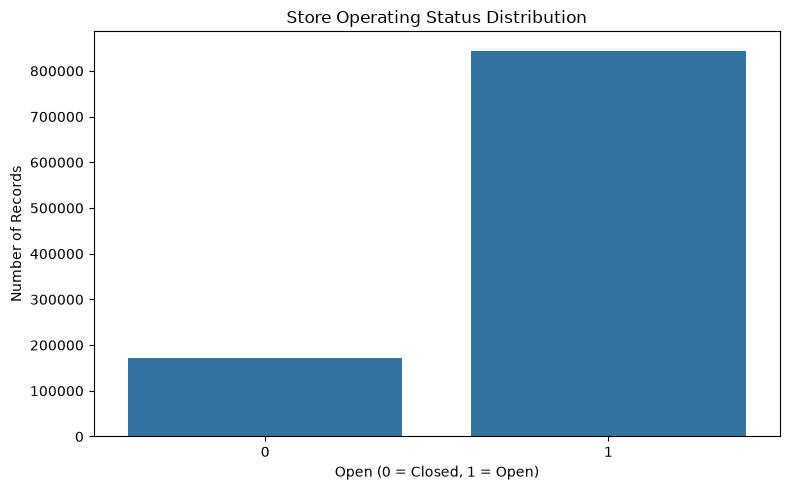

In [7]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Open"
)

plt.title("Store Operating Status Distribution")
plt.xlabel("Open (0 = Closed, 1 = Open)")
plt.ylabel("Number of Records")

plt.tight_layout()
plt.show()

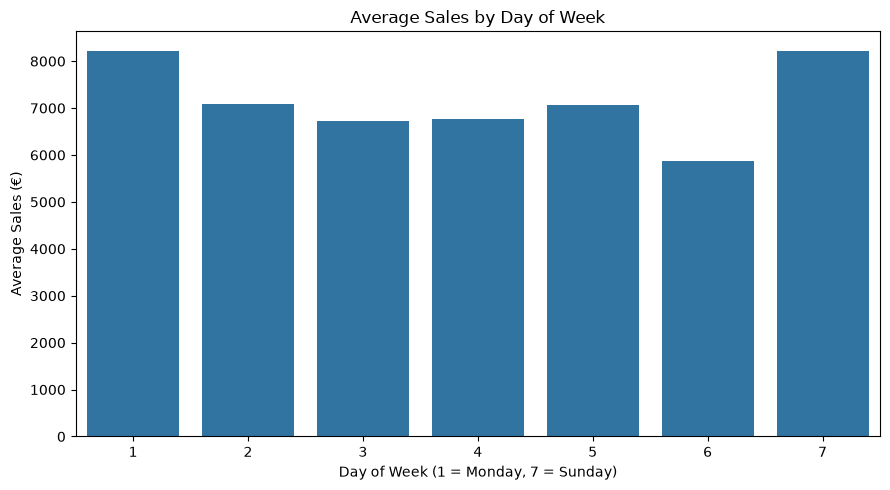

DayOfWeek
1    8216.073074
2    7088.113656
3    6728.122978
4    6767.310159
5    7072.677012
6    5874.840238
7    8224.723908
Name: Sales, dtype: float64

In [8]:
weekday_sales = (
    df[df["Open"] == 1]
    .groupby("DayOfWeek")["Sales"]
    .mean()
)

plt.figure(figsize=(9, 5))

sns.barplot(
    x=weekday_sales.index,
    y=weekday_sales.values
)

plt.title("Average Sales by Day of Week")
plt.xlabel("Day of Week (1 = Monday, 7 = Sunday)")
plt.ylabel("Average Sales (€)")

plt.tight_layout()
plt.show()

display(weekday_sales)

In [9]:
promo_sales = (
    df[df["Open"] == 1]
    .groupby("Promo")
    .agg(
        Average_Sales=("Sales", "mean"),
        Median_Sales=("Sales", "median"),
        Total_Sales=("Sales", "sum"),
        Record_Count=("Sales", "count")
    )
)

display(promo_sales)

,Average_Sales,Median_Sales,Total_Sales,Record_Count
Promo,,,,
0,5929.407603,5459.0,2771974337,467496
1,8228.281239,7649.0,3101206286,376896


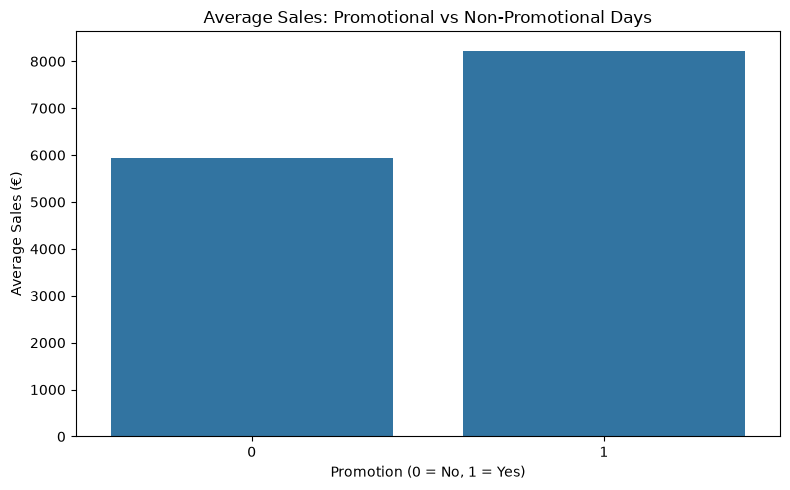

In [10]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df[df["Open"] == 1],
    x="Promo",
    y="Sales",
    errorbar=None
)

plt.title("Average Sales: Promotional vs Non-Promotional Days")
plt.xlabel("Promotion (0 = No, 1 = Yes)")
plt.ylabel("Average Sales (€)")

plt.tight_layout()
plt.show()

In [11]:
store_type_analysis = (
    df[df["Open"] == 1]
    .groupby("StoreType")
    .agg(
        Total_Sales=("Sales", "sum"),
        Average_Sales=("Sales", "mean"),
        Average_Customers=("Customers", "mean"),
        Store_Count=("Store", "nunique")
    )
    .sort_values("Average_Sales", ascending=False)
)

display(store_type_analysis)

,Total_Sales,Average_Sales,Average_Customers,Store_Count
StoreType,,,,
b,159231395,10231.407505,2021.822335,17
c,783221426,6932.512755,815.465887,148
a,3165334859,6925.167661,795.361469,602
d,1765392943,6822.141881,606.339876,348


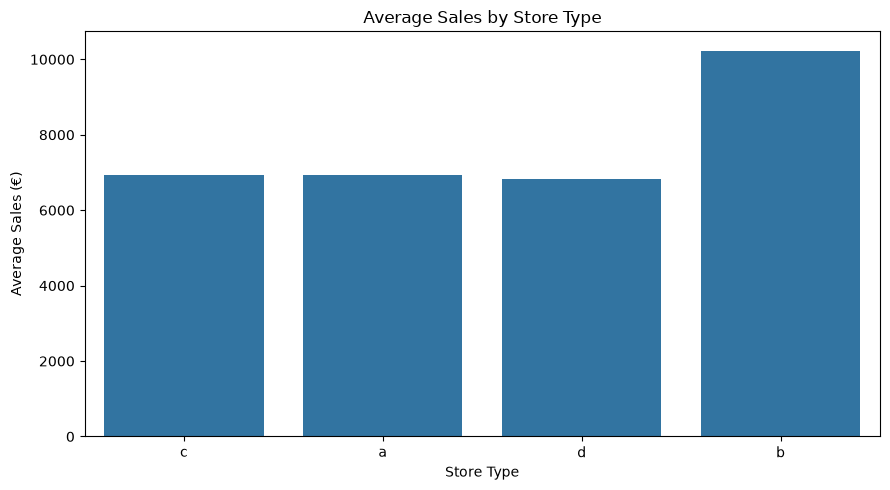

In [12]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=df[df["Open"] == 1],
    x="StoreType",
    y="Sales",
    estimator="mean",
    errorbar=None
)

plt.title("Average Sales by Store Type")
plt.xlabel("Store Type")
plt.ylabel("Average Sales (€)")

plt.tight_layout()
plt.show()

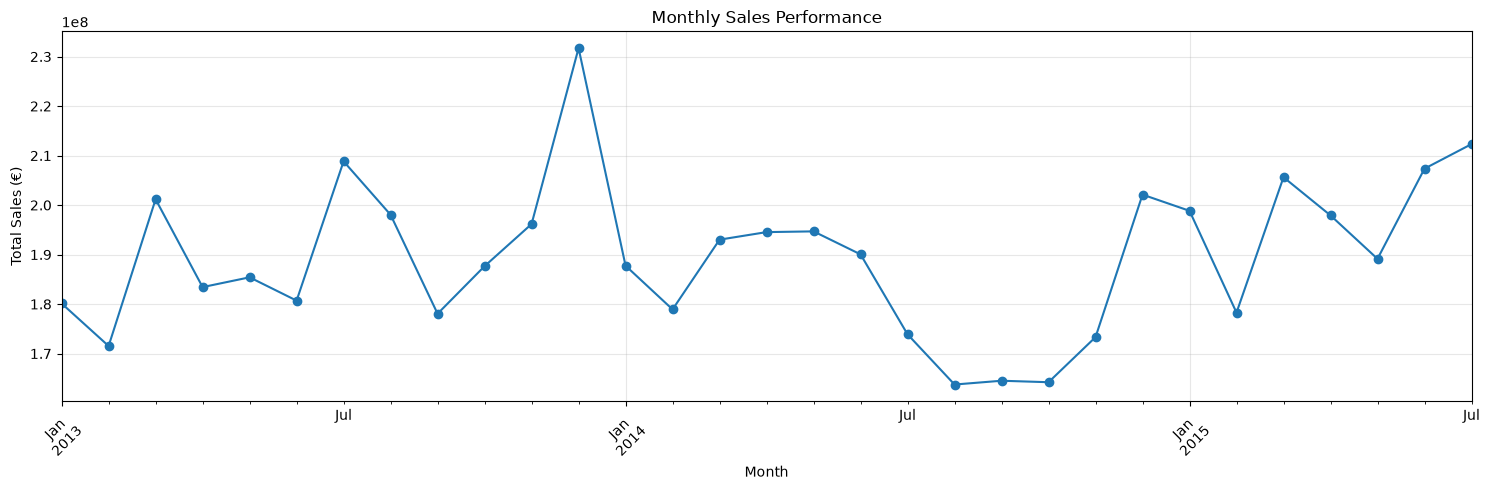

In [13]:
monthly_sales = (
    df[df["Open"] == 1]
    .groupby(df["Date"].dt.to_period("M"))["Sales"]
    .sum()
)

plt.figure(figsize=(15, 5))

monthly_sales.plot(
    kind="line",
    marker="o"
)

plt.title("Monthly Sales Performance")
plt.xlabel("Month")
plt.ylabel("Total Sales (€)")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [14]:
holiday_analysis = (
    df[df["Open"] == 1]
    .groupby(["StateHoliday", "SchoolHoliday"])
    .agg(
        Average_Sales=("Sales", "mean"),
        Average_Customers=("Customers", "mean"),
        Records=("Sales", "count")
    )
    .reset_index()
)

display(holiday_analysis)

,StateHoliday,SchoolHoliday,Average_Sales,Average_Customers,Records
0,0,0,6895.153041,757.354300,680339
1,0,1,7196.896238,781.770153,163143
2,a,0,8492.066102,1266.113559,590
3,a,1,8461.403846,1353.259615,104
4,b,0,34781.166667,5076.166667,6
5,b,1,8813.359712,1540.589928,139
6,c,1,9743.746479,1569.225352,71


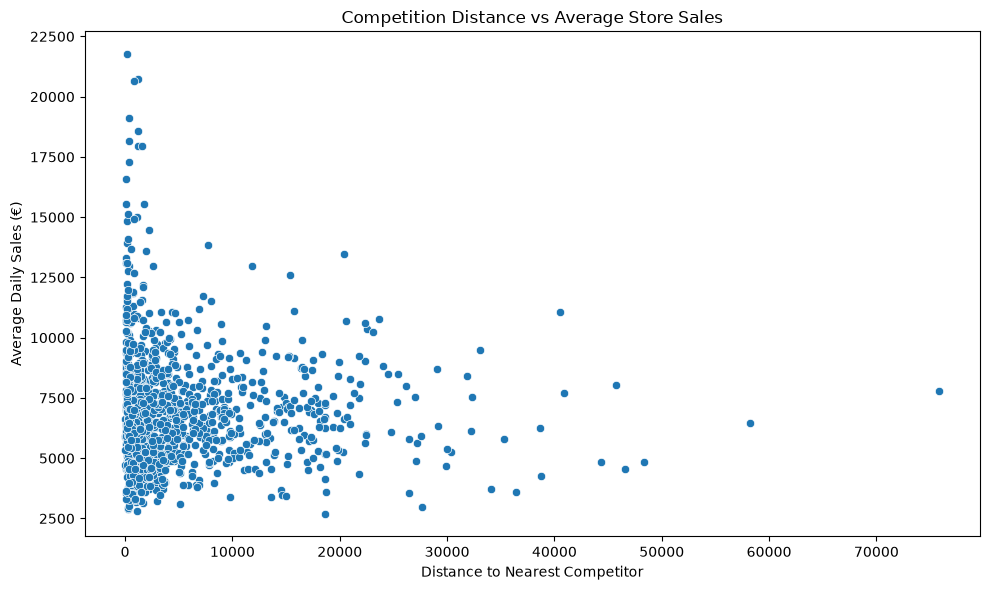

In [15]:
competition_analysis = (
    df[df["Open"] == 1]
    .groupby("Store")
    .agg(
        Average_Sales=("Sales", "mean"),
        Competition_Distance=("CompetitionDistance", "first"),
        Average_Customers=("Customers", "mean")
    )
    .dropna(subset=["Competition_Distance"])
)

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=competition_analysis,
    x="Competition_Distance",
    y="Average_Sales"
)

plt.title("Competition Distance vs Average Store Sales")
plt.xlabel("Distance to Nearest Competitor")
plt.ylabel("Average Daily Sales (€)")

plt.tight_layout()
plt.show()

In [16]:
assortment_analysis = (
    df[df["Open"] == 1]
    .groupby("Assortment")
    .agg(
        Average_Sales=("Sales", "mean"),
        Average_Customers=("Customers", "mean"),
        Total_Sales=("Sales", "sum"),
        Store_Count=("Store", "nunique")
    )
)

display(assortment_analysis)

,Average_Sales,Average_Customers,Total_Sales,Store_Count
Assortment,,,,
a,6621.017039,747.943822,2945750070,593
b,8639.346322,2066.795543,70946312,9
c,7300.526339,752.169959,2856484241,513



# 5. Exploratory Data Analysis – Key Findings

## 5.1 Dataset Overview

The Rossmann dataset contains over one million historical sales
records across 1,115 stores. The training dataset covers January
2013 to July 2015 and provides information about sales, customers,
promotions, holidays and store characteristics.

The initial inspection identified no duplicate records or missing
values in the training dataset. Missing values were primarily
concentrated in the store information dataset.

## 5.2 Key Business Insights

1. **Store Operations:** Approximately 83% of historical records
   represent operational days, while the remaining records
   correspond to closed stores.

2. **Weekly Sales Patterns:** Monday and Sunday demonstrate the
   highest average daily sales, whereas Saturday records the
   lowest average sales.

3. **Promotional Impact:** Promotional days exhibit approximately
   38.8% higher average sales than non-promotional days.

4. **Store Type Performance:** Store Type B records the highest
   average daily sales, although it represents a relatively small
   number of stores.

## 5.3 Data Quality Observations

- The training dataset contains no missing values.
- Store information contains missing competition and Promo2 data.
- The testing dataset contains 11 missing operating-status values.
- Closed-store observations have zero recorded sales and customers.
- Store characteristics provide additional information for
  business performance analysis.

## 5.4 Implications for Machine Learning

The exploratory analysis identifies several potentially useful
predictors of sales:

- Historical date and weekday information.
- Store characteristics.
- Promotional activity.
- Public and school holidays.
- Competition information.
- Seasonal patterns.

Customer counts will be retained for historical BI analysis
but excluded from future-sales prediction because they are
not available in the original test dataset.

## 5.5 Conclusion

The exploratory analysis establishes a foundation for RetailIQ,
revealing meaningful relationships between sales performance,
store characteristics, promotional activity and operating patterns.

These findings will guide the next stage of development:
data preparation, feature engineering and machine learning
model development.

The objective is to develop a predictive analytics system
that combines historical business intelligence with
machine learning-based sales forecasting to support
better retail business decisions.
